# 05 · External validation on US emergency departments (NHAMCS 2022)

Does the vitals model, built on 1,262 Korean patients, still work on a different country's patients?

- **External data:** CDC *National Hospital Ambulatory Medical Care Survey* (NHAMCS) 2022, emergency department
  public-use file: a national sample of US ED visits with triage vitals and the nurse's triage level (immediacy 1–5).
- **The deployed model is used exactly as saved** (`models/urgent_model.joblib`); nothing is refitted on US data,
  except the in-domain reference model in section 5, which is labelled as such.
- **Urgent** = triage level 1–2 (immediate / emergent), matching KTAS 1–2.

Coding decisions are documented in `../src/nhamcs.py`.

In [1]:
import sys, json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import ktas_data as kd
import news2
import nhamcs
import vitals_classifier as vc

pd.set_option("display.width", 200)
ROOT = Path.cwd().parent
FIG_DIR, MODEL_DIR = ROOT / "figures", ROOT / "models"
OUT_DIR = ROOT / "data" / "external" / "nhamcs_2022" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)
meta = json.loads((MODEL_DIR / "model_meta.json").read_text())
THRESHOLD = meta["threshold"]

## 1. Load and map NHAMCS onto the training table

In [2]:
nh, log = nhamcs.harmonize(nhamcs.load())
log

,step,n
0,NHAMCS 2022 ED visits,16025
1,aged 16 or over,12999
2,triage level 1-5 recorded,8412
3,implausible values set to missing: 56 values,8412


## 2. How different are the two populations?

In [3]:
ktas = kd.load_clean()
ktas["urgent"] = vc.urgent_target(ktas)

def describe(d):
    row = {"visits": len(d), "median age": d.age.median(), "% male": d.is_male.mean() * 100,
           "% urgent (level 1-2)": d.urgent.mean() * 100}
    for v in kd.VITALS:
        row[f"% {v} missing"] = d[v].isna().mean() * 100
    row["% consciousness missing"] = d.mental.isna().mean() * 100
    return row

pd.DataFrame({"KTAS (Korea, training)": describe(ktas), "NHAMCS 2022 (US, external)": describe(nh)}).round(1)

,"KTAS (Korea, training)","NHAMCS 2022 (US, external)"
visits,1262.0,8412.0
median age,57.0,48.0
% male,52.1,46.2
% urgent (level 1-2),19.4,18.6
% sbp missing,2.0,1.3
% dbp missing,2.3,1.4
% hr missing,1.6,1.9
% rr missing,1.7,2.1
% temp_c missing,1.3,3.0
% spo2 missing,54.9,1.9


Two differences matter:

- **Labels:** KTAS labels come from an expert panel; NHAMCS levels are the triage nurse's decision, using each ED's own system.
- **Missing values:** SpO2 is missing for 55% of Korean visits but almost never in the US data, and NHAMCS has no
  consciousness field at all.

In the Korean data, whether SpO2 was measured carries information:

In [4]:
ktas.groupby(ktas.spo2.isna().map({True: "SpO2 not recorded", False: "SpO2 recorded"})) \
    .urgent.agg(visits="size", urgent_rate="mean").round(3)

,visits,urgent_rate
spo2,,
SpO2 not recorded,693,0.130
SpO2 recorded,569,0.272


## 3. Score the US patients with the saved model

In [5]:
model = joblib.load(MODEL_DIR / "urgent_model.joblib")
X_nh = vc.build_X(nh)                         # computes NEWS2; consciousness missing -> not scored
nh["news2"] = X_nh["news2"]
nh["news2_floor"] = news2.score_frame(nh)["floor_priority"].to_numpy()
nh["p_urgent"] = vc.urgent_proba(model, X_nh)
y = nh.urgent.to_numpy()
print(f"{len(nh)} US visits scored, {y.sum()} urgent ({y.mean():.1%})")

8412 US visits scored, 1564 urgent (18.6%)


## 4. Discrimination: AUROC for urgent (level 1–2)

95% CIs from 2,000 bootstrap resamples. *Weighted* AUROC uses the NHAMCS survey weights (`PATWT`), i.e. how the model would
perform across all US ED visits rather than the sampled ones.

In [6]:
def auc_row(name, s, data="NHAMCS (external)"):
    auc, lo, hi = vc.bootstrap(roc_auc_score, y, s)
    return {"model": name, "data": data, "AUROC": round(auc, 3), "95% CI": f"{lo:.2f}-{hi:.2f}",
            "weighted AUROC": round(roc_auc_score(y, s, sample_weight=nh.weight), 3)}

# Variant: same model refitted on Korean data without the consciousness input,
# since NHAMCS never records it
feats_no_mental = [f for f in vc.FEATURES if f != "mental"]
X_ktas = vc.build_X(ktas)
params = meta["urgent_model"]["params"]
no_mental = vc.make_hgb(**params).fit(X_ktas[feats_no_mental], ktas.urgent)
nh["p_urgent_no_mental"] = vc.urgent_proba(no_mental, X_nh[feats_no_mental])

rows = [auc_row("NEWS2", nh.news2),
        auc_row("Vitals model (as deployed)", nh.p_urgent),
        auc_row("Vitals model, refitted without consciousness", nh.p_urgent_no_mental)]
auc_table = pd.DataFrame(rows)
d_, lo, hi = vc.bootstrap(roc_auc_score, y, nh.p_urgent, nh.news2)
print(f"Vitals model minus NEWS2 on US data: {d_:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")
auc_table

Vitals model minus NEWS2 on US data: -0.003 (95% CI -0.022 to +0.018)


,model,data,AUROC,95% CI,weighted AUROC
0,NEWS2,NHAMCS (external),0.624,0.61-0.64,0.626
1,Vitals model (as deployed),NHAMCS (external),0.621,0.61-0.64,0.633
2,"Vitals model, refitted without consciousness",NHAMCS (external),0.618,0.60-0.63,0.629


For comparison, on the Korean test set (notebook 03): NEWS2 0.69, vitals model 0.78.

### Is it the SpO2-missingness signal?

In Korea, patients whose SpO2 was measured were twice as likely to be urgent, so the model could have learnt the
*nurses' habit* of measuring SpO2 rather than physiology, a signal that disappears in US data where SpO2 is nearly
always recorded. Test: refit with missing SpO2 filled by the median (signal hidden), and compare on Korean development
data (5-fold CV, test set untouched) and on US data.

In [7]:
dev = ktas[ktas.split != "test"].reset_index(drop=True)
X_dev, y_dev = vc.build_X(dev), dev.urgent.to_numpy()
med = X_dev.spo2.median()
hide = lambda d: d.assign(spo2=d.spo2.fillna(med))
rows = []
for name, f in [("SpO2 missingness visible (current)", lambda d: d), ("SpO2 missingness hidden", hide)]:
    p_cv = cross_val_predict(vc.make_hgb(**params), f(X_dev), y_dev,
                             cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    m = vc.make_hgb(**params).fit(f(X_ktas), ktas.urgent)
    rows.append({"variant": name, "Korea dev CV AUROC": round(roc_auc_score(y_dev, p_cv), 3),
                 "US external AUROC": round(roc_auc_score(y, vc.urgent_proba(m, f(X_nh))), 3)})
rows.append({"variant": "NEWS2 (reference)", "Korea dev CV AUROC": round(roc_auc_score(y_dev, X_dev.news2), 3),
             "US external AUROC": round(roc_auc_score(y, nh.news2), 3)})
pd.DataFrame(rows)

,variant,Korea dev CV AUROC,US external AUROC
0,SpO2 missingness visible (current),0.826,0.621
1,SpO2 missingness hidden,0.819,0.626
2,NEWS2 (reference),0.689,0.624


Hiding the signal changes almost nothing in either country, so it does **not** explain the drop. NEWS2, a fixed
formula, falls by a similar amount: vital signs are simply less tied to the US nurses' triage levels than to the Korean
expert levels.

## 5. Reference: how well can vitals do on US data at all?

A model with the same settings, trained **on NHAMCS itself** (5-fold cross-validation). This is an upper reference for what
these inputs can achieve in US data; the gap to section 4 is the cost of transferring from Korea.

In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
X_in = X_nh[feats_no_mental]
p_in = cross_val_predict(vc.make_hgb(**params), X_in, y, cv=cv, method="predict_proba")[:, 1]
X_in_amb = X_in.assign(ambulance=nh.ambulance)
p_in_amb = cross_val_predict(vc.make_hgb(**params), X_in_amb, y, cv=cv, method="predict_proba")[:, 1]
ref = pd.DataFrame([auc_row("Same settings, trained on NHAMCS (CV)", p_in, "NHAMCS (in-domain)"),
                    auc_row("  + arrived by ambulance", p_in_amb, "NHAMCS (in-domain)")])
ref

,model,data,AUROC,95% CI,weighted AUROC
0,"Same settings, trained on NHAMCS (CV)",NHAMCS (in-domain),0.70,0.69-0.72,0.708
1,+ arrived by ambulance,NHAMCS (in-domain),0.72,0.71-0.73,0.733


## 6. Operating points at the thresholds chosen on Korean data

In [9]:
def op(name, flag):
    flag = np.asarray(flag)
    return {"rule": name, "% flagged": round(flag.mean() * 100, 1),
            "sensitivity": round(flag[y == 1].mean(), 2), "specificity": round((~flag[y == 0]).mean(), 2),
            "PPV": round(y[flag].mean(), 2)}

pd.DataFrame([op("NEWS2 >= 5", nh.news2 >= 5), op("NEWS2 >= 3", nh.news2 >= 3),
              op(f"Vitals model p >= {THRESHOLD:.2f}", nh.p_urgent >= THRESHOLD)])

,rule,% flagged,sensitivity,specificity,PPV
0,NEWS2 >= 5,3.8,0.11,0.98,0.54
1,NEWS2 >= 3,13.4,0.28,0.90,0.39
2,Vitals model p >= 0.14,48.9,0.63,0.54,0.24


## 7. Calibration

Does "30% chance urgent" still mean 30% in the US? Observed vs predicted by fifths of predicted risk.

In [10]:
p = nh.p_urgent.to_numpy()
print(f"mean predicted {p.mean():.3f} vs observed {y.mean():.3f};  Brier {brier_score_loss(y, p):.3f} "
      f"(base rate only: {brier_score_loss(y, np.full(len(y), y.mean())):.3f})")
bins = pd.qcut(p, 5, duplicates="drop")
pd.DataFrame({"mean predicted": pd.Series(p).groupby(bins, observed=True).mean(),
              "observed urgent": pd.Series(y).groupby(bins, observed=True).mean(),
              "visits": pd.Series(p).groupby(bins, observed=True).size()}).round(3)

mean predicted 0.177 vs observed 0.186;  Brier 0.151 (base rate only: 0.151)


,mean predicted,observed urgent,visits
"(0.008820000000000001, 0.0587]",0.041,0.121,1683
"(0.0587, 0.105]",0.079,0.137,1682
"(0.105, 0.172]",0.137,0.164,1682
"(0.172, 0.257]",0.211,0.216,1682
"(0.257, 0.978]",0.415,0.292,1683


## 8. Safety floor on US patients

Over-triage = floor more urgent than the nurse's level.

In [11]:
clf_floor = np.where(nh.p_urgent >= THRESHOLD, 3, 5)
combined = np.minimum(nh.news2_floor.to_numpy(), clf_floor)
def floor_stats(name, floor):
    urgent = y == 1
    return {"floor from": name, "urgent patients given a floor": f"{(urgent & (floor <= 3)).mean() / urgent.mean():.0%}",
            "over-triaged visits": f"{(floor < nh.triage_level.to_numpy()).mean():.1%}"}
pd.DataFrame([floor_stats("NEWS2 only", nh.news2_floor.to_numpy()), floor_stats("NEWS2 + classifier", combined)])

,floor from,urgent patients given a floor,over-triaged visits
0,NEWS2 only,21%,1.6%
1,NEWS2 + classifier,64%,10.4%


## 9. Figure

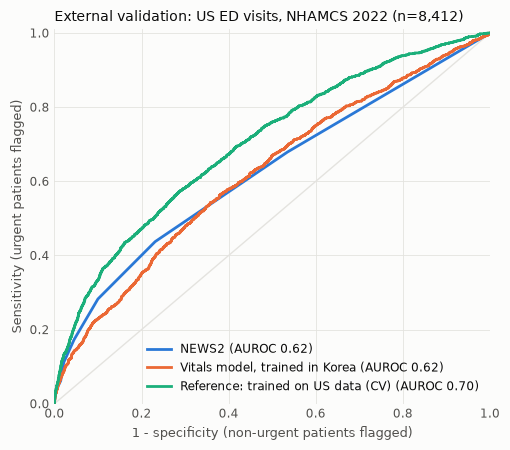

In [12]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
curves = [("NEWS2", nh.news2, "#2a78d6"),
          ("Vitals model, trained in Korea", nh.p_urgent, "#eb6834"),
          ("Reference: trained on US data (CV)", p_in, "#1baf7a")]
fig, ax = plt.subplots(figsize=(5.2, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot([0, 1], [0, 1], color=GRID, lw=1, zorder=0)
for name, s, color in curves:
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUROC {roc_auc_score(y, s):.2f})")
ax.set_xlabel("1 - specificity (non-urgent patients flagged)", color=MUTED, fontsize=9)
ax.set_ylabel("Sensitivity (urgent patients flagged)", color=MUTED, fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
ax.grid(color=GRID, lw=0.6)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=8.5, labelcolor=INK)
ax.set_title(f"External validation: US ED visits, NHAMCS 2022 (n={len(nh):,})", loc="left", fontsize=10, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_external_nhamcs.png", dpi=300, facecolor=SURFACE)
plt.show()

## 10. Save

In [13]:
nh.to_csv(OUT_DIR / "nhamcs_scored.csv", index=False)
results = pd.concat([auc_table, ref], ignore_index=True)
results.to_csv(OUT_DIR / "external_auroc.csv", index=False)
print("Saved to", OUT_DIR)

Saved to C:\Users\Claeb\anaconda3\BN4601a\group_project\vitals\data\external\nhamcs_2022\processed


## Summary for the report

(Run of 19 Oct 2026. NHAMCS 2022 ED public-use file, adults ≥ 16 with a recorded triage level 1–5.)

- **Cohort:** 8,412 US ED visits, 18.6% urgent (immediate/emergent), similar to the Korean 19.4%. SpO2 is almost always
  recorded (vs 55% missing in Korea) and consciousness is never recorded.
- **The learnt model does not transfer better than NEWS2.** External AUROC: vitals model 0.62 (95% CI 0.61–0.64),
  NEWS2 0.62 (0.61–0.64); difference −0.003 (−0.022 to +0.018). Survey-weighted results are the same (0.63).
  On Korean test data the model led NEWS2 by 0.09 (0.78 vs 0.69).
- **Some of the drop is transfer cost, some is the data.** The same settings trained on US data reach 0.70 (0.72 with
  "arrived by ambulance"), so moving from Korea to the US costs about 0.08. But NEWS2 also falls from 0.69 to 0.62:
  vitals are less tied to US nurse triage levels (each ED's own system, often ESI, which rates high-risk complaints such
  as chest pain as level 2 whatever the vitals) than to the Korean expert levels.
- **Not explained by SpO2 missingness:** hiding it changes AUROC by under 0.01 in either country.
- **Thresholds and probabilities shift.** At p ≥ 0.14, sensitivity 0.63 and specificity 0.54 (Korea: 0.81 / 0.59).
  The average risk is right (17.7% predicted vs 18.6% observed), but the spread is too wide: the top fifth is predicted
  42% and observed 29%, and the Brier score is no better than the base rate.
- **Safety floor:** NEWS2-only floor covers 21% of urgent US patients (1.6% over-triage); adding the classifier covers 64%
  (10.4% over-triage).
- **Conclusion:** the NEWS2 formula and safety rule are the parts that travel; the learnt `p_urgent` is specific to the
  Korean data and should be recalibrated or retrained on local data before use elsewhere. Vitals alone are an even weaker
  triage signal in the US, which again supports combining them with the patient's history in the main model.